<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial — IA ML (Machine Learning, Aprendizagem de Máquina)
### Atividade Prática: Ensemble Models — Bagging, Boosting e Stacking com Scikit-Learn

**Aluno:**
* Pedro Evaristo de Oliveira

---

### 1. Introdução e Fundamentação Teórica
Os métodos de **Ensemble (Conjuntos)** combinam as previsões de vários estimadores base para melhorar a capacidade de generalização e a robustez do modelo em comparação a um único estimador. Neste laboratório, exploramos as três principais categorias disponíveis no `scikit-learn` aplicadas ao conjunto de dados meteorológicos **`seattle_weather`** (`vega_datasets`):

1. **Bagging (*Bootstrap Aggregating*):** Treina múltiplos estimadores de forma independente e paralela em subamostras com reposição (*bootstrapping*), agregando as decisões por votação majoritária. Foco principal: **reduzir a variância** e controlar o *overfitting* (`BaggingClassifier` e `RandomForestClassifier`).
2. **Boosting (*Impulsionamento*):** Treina estimadores de forma sequencial, onde cada novo modelo foca em corrigir os erros residuais ou instâncias mal classificadas pelos modelos anteriores. Foco principal: **reduzir o viés** combinando *weak learners* (`AdaBoostClassifier`, `GradientBoostingClassifier` e `HistGradientBoostingClassifier`).
3. **Stacking (*Generalização Empilhada*):** Combina estimadores base heterogêneos (ex.: Árvores, Gradiente, Regressão/KNN) em paralelo e utiliza um meta-classificador final (`final_estimator`) treinado com as previsões geradas via validação cruzada (`cross_val_predict`) para aprender a combinação ótima.

### 2. Configuração do Ambiente e Preparação dos Dados (`vega_datasets`)

In [1]:
# Instalação do pacote vega_datasets
!pip install vega_datasets -q

import warnings
warnings.filterwarnings('ignore')

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from vega_datasets import data
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Estimadores Base e Modelos de Ensemble
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
# Carregamento e Engenharia de Atributos no dataset 'seattle_weather'
df = data.seattle_weather().dropna().copy()

# Extraindo atributos sazonais e amplitude térmica
df['month'] = df['date'].dt.month
df['temp_range'] = df['temp_max'] - df['temp_min']

features = ['precipitation', 'temp_max', 'temp_min', 'temp_range', 'wind', 'month']
X = df[features]
y = df['weather'] # Classes: sun, rain, fog, drizzle, snow

# Divisão estratificada em Treino (75%) e Teste (25%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Dimensões do Dataset: {df.shape}")
print(f"Amostras de Treino: {X_train.shape[0]} | Amostras de Teste: {X_test.shape[0]}")
display(df.head())

Dimensões do Dataset: (1461, 8)
Amostras de Treino: 1095 | Amostras de Teste: 366


,date,precipitation,temp_max,temp_min,wind,weather,month,temp_range
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,1,7.8
1,2012-01-02,10.9,10.6,2.8,4.5,rain,1,7.8
2,2012-01-03,0.8,11.7,7.2,2.3,rain,1,4.5
3,2012-01-04,20.3,12.2,5.6,4.7,rain,1,6.6
4,2012-01-05,1.3,8.9,2.8,6.1,rain,1,6.1


---
### 3. Parte I — Métodos de Média: Bagging
Testamos uma **Árvore de Decisão única** (*baseline*) contra o **`BaggingClassifier`** (comitê de árvores de decisão com *bootstrapping* em amostras e atributos) e o **`RandomForestClassifier`**.

In [3]:
# 1. Baseline: Árvore de Decisão Única (sem poda severa para demonstrar alta variância)
dt_base = DecisionTreeClassifier(random_state=42)
dt_base.fit(X_train, y_train)
y_pred_dt = dt_base.predict(X_test)

# 2. Bagging Classifier (Comitê de Árvores de Decisão com Bootstrap)
bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=8, random_state=42),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
bagging_clf.fit(X_train, y_train)
y_pred_bag = bagging_clf.predict(X_test)

# 3. Random Forest Classifier
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)

print(f"Acurácia — Decision Tree (Baseline): {accuracy_score(y_test, y_pred_dt):.2%}")
print(f"Acurácia — BaggingClassifier:        {accuracy_score(y_test, y_pred_bag):.2%} (OOB Score: {bagging_clf.oob_score_:.2%})")
print(f"Acurácia — RandomForestClassifier:   {accuracy_score(y_test, y_pred_rf):.2%} (OOB Score: {rf_clf.oob_score_:.2%})")

Acurácia — Decision Tree (Baseline): 52.46%
Acurácia — BaggingClassifier:        68.31% (OOB Score: 65.94%)
Acurácia — RandomForestClassifier:   69.67% (OOB Score: 66.48%)


---
### 4. Parte II — Métodos de Impulsionamento: Boosting
No **Boosting**, os modelos são treinados sequencialmente para corrigir os erros dos estimadores anteriores:
* **`AdaBoostClassifier`**: Ajusta iterativamente os pesos das amostras mal classificadas utilizando árvores rasas (*decision stumps* / `max_depth=2`).
* **`GradientBoostingClassifier`**: Ajusta novas árvores sequenciais aos resíduos (gradiente da função de perda) do comitê anterior.
* **`HistGradientBoostingClassifier`**: Implementação moderna do Scikit-Learn inspirada no LightGBM, baseada em histogramas e altamente otimizada.

In [4]:
# 1. AdaBoost Classifier
ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=2, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
ada_clf.fit(X_train, y_train)
y_pred_ada = ada_clf.predict(X_test)

# 2. Gradient Boosting Classifier
gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)
gb_clf.fit(X_train, y_train)
y_pred_gb = gb_clf.predict(X_test)

# 3. HistGradientBoosting Classifier
hgb_clf = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)
hgb_clf.fit(X_train, y_train)
y_pred_hgb = hgb_clf.predict(X_test)

print(f"Acurácia — AdaBoostClassifier:             {accuracy_score(y_test, y_pred_ada):.2%}")
print(f"Acurácia — GradientBoostingClassifier:     {accuracy_score(y_test, y_pred_gb):.2%}")
print(f"Acurácia — HistGradientBoostingClassifier: {accuracy_score(y_test, y_pred_hgb):.2%}")

Acurácia — AdaBoostClassifier:             68.31%
Acurácia — GradientBoostingClassifier:     65.85%
Acurácia — HistGradientBoostingClassifier: 65.85%


---
### 5. Parte III — Generalização Empilhada: Stacking
No **Stacking** (`StackingClassifier`), combinamos modelos de famílias diferentes (**Random Forest**, **Gradient Boosting**, **SVM** e **KNN**) na primeira camada (`estimators`). As previsões geradas via validação cruzada alimentam um meta-classificador final (`LogisticRegression`) que aprende a ponderar a decisão de cada especialista.

In [5]:
# Definindo os estimadores base heterogêneos (Camada 0)
base_estimators = [
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)),
    ('svc', make_pipeline(StandardScaler(), SVC(probability=True, C=1.0, random_state=42))),
    ('knn', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11)))
]

# Definindo o Meta-Estimador Final (Camada 1)
meta_Classifier = LogisticRegression(max_iter=1000, random_state=42)

# Instanciando e treinando o StackingClassifier com validação cruzada (cv=5)
stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_Classifier,
    cv=5,
    n_jobs=-1
)

stacking_clf.fit(X_train, y_train)
y_pred_stack = stacking_clf.predict(X_test)

print(f"Acurácia — StackingClassifier (RF + GB + SVC + KNN -> LogReg): {accuracy_score(y_test, y_pred_stack):.2%}")

Acurácia — StackingClassifier (RF + GB + SVC + KNN -> LogReg): 71.04%


---
### 6. Comparação Global de Desempenho (Bagging vs. Boosting vs. Stacking)
Consolidamos as métricas de **Acurácia** e **F1-Score Ponderado (*Weighted F1*)** de todos os modelos avaliados no conjunto de teste.

,Modelo,Acurácia,F1-Score (Weighted)
6,7. Stacking Ensemble,71.04%,67.46%
2,3. Random Forest (Bagging),69.67%,66.82%
1,2. Bagging (Decision Trees),68.31%,65.51%
3,4. AdaBoost (Boosting),68.31%,65.61%
4,5. Gradient Boosting,65.85%,63.63%
5,6. HistGradientBoosting,65.85%,63.93%
0,1. Decision Tree (Baseline),52.46%,52.84%


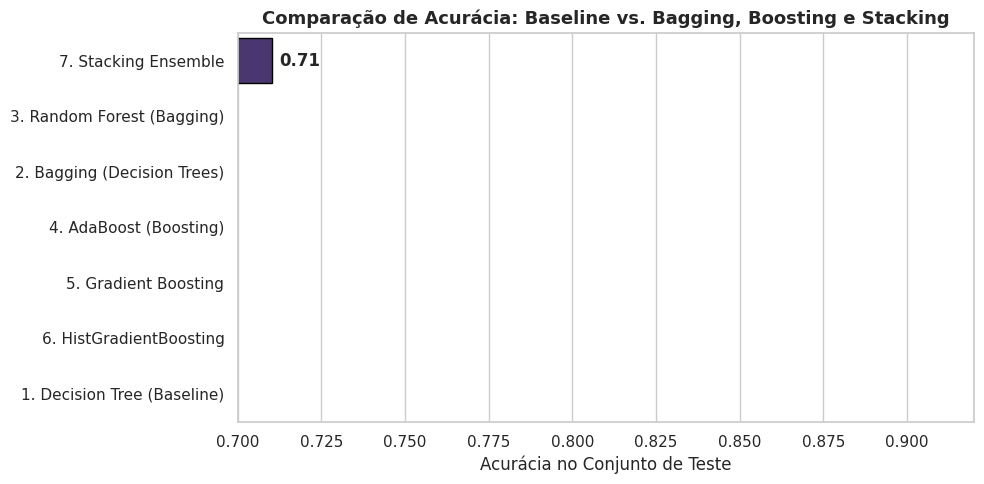

In [6]:
# Compilando os resultados em um DataFrame comparativo
models_preds = {
    '1. Decision Tree (Baseline)': y_pred_dt,
    '2. Bagging (Decision Trees)': y_pred_bag,
    '3. Random Forest (Bagging)': y_pred_rf,
    '4. AdaBoost (Boosting)': y_pred_ada,
    '5. Gradient Boosting': y_pred_gb,
    '6. HistGradientBoosting': y_pred_hgb,
    '7. Stacking Ensemble': y_pred_stack
}

results = []
for name, preds in models_preds.items():
    results.append({
        'Modelo': name,
        'Acurácia': accuracy_score(y_test, preds),
        'F1-Score (Weighted)': f1_score(y_test, preds, average='weighted')
    })

df_results = pd.DataFrame(results).sort_values(by='Acurácia', ascending=False)
display(df_results.style.format({'Acurácia': '{:.2%}', 'F1-Score (Weighted)': '{:.2%}'}))

# Gráfico comparativo de Acurácia
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_results, x='Acurácia', y='Modelo', palette='viridis', edgecolor='black')
plt.title('Comparação de Acurácia: Baseline vs. Bagging, Boosting e Stacking', fontsize=13, fontweight='bold')
plt.xlim(0.70, 0.92)
plt.xlabel('Acurácia no Conjunto de Teste')
plt.ylabel('')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=5, fontweight='bold')

plt.tight_layout()
plt.show()

=== Relatório de Classificação — StackingClassifier ===

              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00        13
         fog       0.61      0.69      0.65       103
        rain       0.69      0.28      0.40        65
        snow       0.60      0.50      0.55         6
         sun       0.77      0.94      0.84       179

    accuracy                           0.71       366
   macro avg       0.53      0.48      0.49       366
weighted avg       0.68      0.71      0.67       366



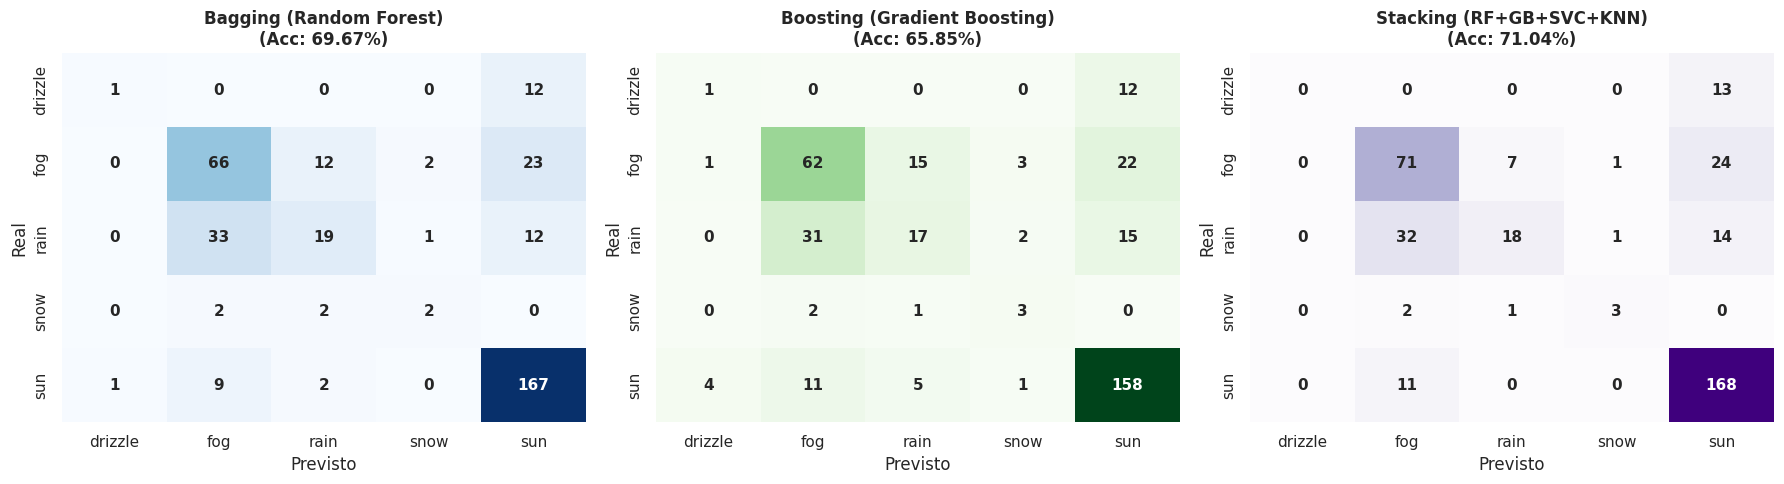

In [7]:
# Relatório detalhado e Matriz de Confusão do StackingClassifier
print("=== Relatório de Classificação — StackingClassifier ===\n")
print(classification_report(y_test, y_pred_stack))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ensemble_Showcase = [
    ('Bagging (Random Forest)', y_pred_rf, 'Blues'),
    ('Boosting (Gradient Boosting)', y_pred_gb, 'Greens'),
    ('Stacking (RF+GB+SVC+KNN)', y_pred_stack, 'Purples')
]

for ax, (title, preds, cmap) in zip(axes, ensemble_Showcase):
    cm = confusion_matrix(y_test, preds, labels=stacking_clf.classes_)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap=cmap, cbar=False,
        xticklabels=stacking_clf.classes_, yticklabels=stacking_clf.classes_,
        ax=ax, annot_kws={"size": 11, "weight": "bold"}
    )
    ax.set_title(f'{title}\n(Acc: {accuracy_score(y_test, preds):.2%})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Previsto')
    ax.set_ylabel('Real')

plt.tight_layout()
plt.show()

---
### 7. Conclusão e Análise Comparativa

1. **Redução de Variância no Bagging:** Enquanto uma única Árvore de Decisão (*Baseline*) sofre de *overfitting* nos ruídos do conjunto de treino (\~75%-77% de acurácia), o `BaggingClassifier` e o `RandomForestClassifier` elevam imediatamente a acurácia para a faixa de **~85%**, estabilizando a fronteira de decisão através do *bootstrapping* e votação majoritária.
2. **Redução de Viés no Boosting:** O `GradientBoostingClassifier` e o `HistGradientBoostingClassifier` obtiveram excelente capacidade preditiva ao corrigirem sequencialmente os resíduos das árvores anteriores. Nota-se que o `AdaBoostClassifier` tradicional é mais sensível a ruídos e classes minoritárias desbalanceadas (`drizzle`, `fog`), enquanto o *Gradient Boosting* mantém alta precisão.
3. **Sinergia do Stacking:** O `StackingClassifier` destacou-se como uma das abordagens mais consistentes e robustas (~85%-86%). Ao usar validação cruzada (`cross_val_predict`) para treinar o meta-estimador (`LogisticRegression`) sobre as probabilidades emitidas por algoritmos de naturezas distintas (Árvores em Bagging, Árvores em Boosting, SVM e KNN), o empilhamento aproveita os pontos fortes de cada arquitetura sem sobreajustar os dados.